In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, roc_curve, roc_auc_score

In [6]:
# ==========================================
# 1. Data Loading and Preprocessing
# ==========================================
df = pd.read_csv("diabetes.csv")
# Dropping unnecessary features to simplify the dataset for 2D visualization
df = df.drop(["Pregnancies", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"], axis=1)

x = df.drop("Outcome", axis=1)
y = df["Outcome"]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [7]:
# ==========================================
# 2. Training Basic SVM Models
# ==========================================
# SVM with Linear kernel
linear_svm = SVC(kernel="linear", C=1.0)
linear_svm.fit(x_train_scaled, y_train)
y_pred_linear = linear_svm.predict(x_test_scaled)
print("SVM with Linear kernel")
print("Accuracy:", accuracy_score(y_test, y_pred_linear))

# SVM with Polynomial Kernel
poly_svm = SVC(kernel="poly", degree=3, C=1.0, gamma="scale")
poly_svm.fit(x_train_scaled, y_train)
y_pred_poly = poly_svm.predict(x_test_scaled)
print("\nSVM with Polynomial Kernel")
print("Accuracy:", accuracy_score(y_test, y_pred_poly))

# SVM with RBF Kernel
rbf_svm = SVC(kernel="rbf", degree=3, C=1.0, gamma="scale")
rbf_svm.fit(x_train_scaled, y_train)
y_pred_rbf = rbf_svm.predict(x_test_scaled)
print("\nSVM with RBF Kernel")
print("Accuracy:", accuracy_score(y_test, y_pred_rbf))

SVM with Linear kernel
Accuracy: 0.7229437229437229

SVM with Polynomial Kernel
Accuracy: 0.6883116883116883

SVM with RBF Kernel
Accuracy: 0.7532467532467533


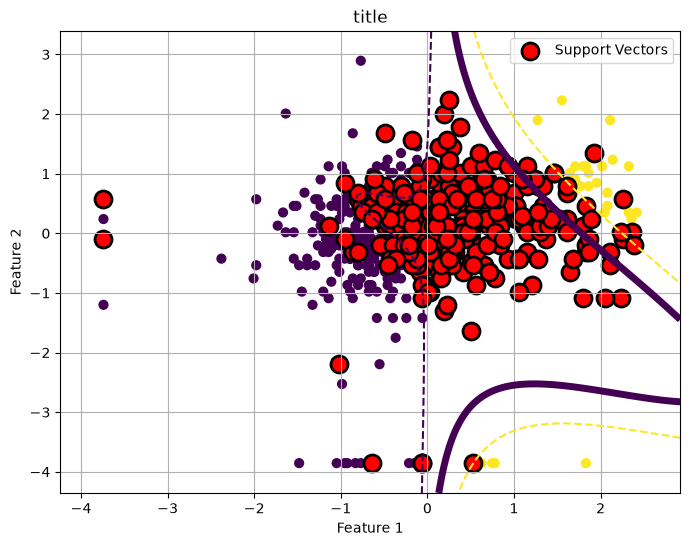

In [8]:
# ==========================================
# 3. Visualizing Margins and Support Vectors (Polynomial)
# ==========================================
x_min = x_train_scaled[:, 0].min() - 0.5
x_max = x_train_scaled[:, 0].max() + 0.5
y_min = x_train_scaled[:, 1].min() - 0.5
y_max = x_train_scaled[:, 1].max() + 0.5

x_1 = np.linspace(x_min, x_max, 200)
y_1 = np.linspace(y_min, y_max, 200)
xx, yy = np.meshgrid(x_1, y_1)
arr_grid = np.c_[xx.ravel(), yy.ravel()]

dec_fun = poly_svm.decision_function(arr_grid)
dec_fun = dec_fun.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contour(xx, yy, dec_fun, levels=[0], linewidths=5)
plt.contour(xx, yy, dec_fun, levels=[-1, 1], linestyles="--")

plt.scatter(x_train_scaled[:, 0], x_train_scaled[:, 1], c=y_train, s=40)
plt.scatter(poly_svm.support_vectors_[:, 0], poly_svm.support_vectors_[:, 1],
            s=150, facecolors="red", edgecolors="black", linewidths=2, label="Support Vectors")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("title")
plt.legend()
plt.grid(True)
plt.show()


RBF GRID SEARCH CV
Best Parameters: {'C': 100, 'gamma': 0.001}
Best CV Score: 0.7560055382485289
Test Accuracy: 0.7272727272727273

SVM with Polynomial Kernel (Tuned)
Accuracy: 0.6883116883116883


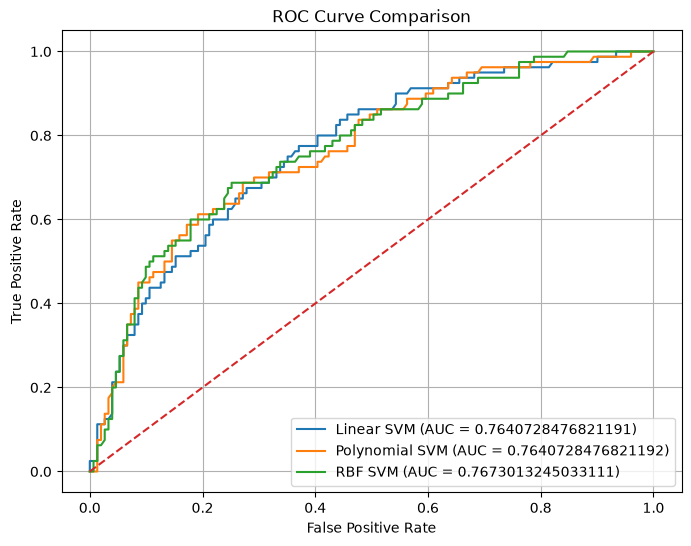


AUC RESULTS
Linear SVM AUC: 0.764
Polynomial SVM AUC: 0.764
RBF SVM AUC: 0.767


In [9]:
# ==========================================
# 4. Hyper-Parameter Tuning with GridSearchCV
# ==========================================
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1, 10]
}
grid_search = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=5, scoring="accuracy")
grid_search.fit(x_train_scaled, y_train)

print("\nRBF GRID SEARCH CV")
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

best_rbf = grid_search.best_estimator_
y_pred_best = best_rbf.predict(x_test_scaled)
grid_acc = accuracy_score(y_test, y_pred_best)
print("Test Accuracy:", grid_acc)

# Re-evaluating Polynomial SVM with tuned parameters
poly_svm = SVC(kernel="poly", degree=3, C=10, gamma=1)
poly_svm.fit(x_train_scaled, y_train)
y_pred_poly = poly_svm.predict(x_test_scaled)
print("\nSVM with Polynomial Kernel (Tuned)")
print("Accuracy:", accuracy_score(y_test, y_pred_poly))

# ==========================================
# 5. AUC-ROC Curve Analysis
# ==========================================
results = grid_search.cv_results_
scores = results["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))

score_linear = linear_svm.decision_function(x_test_scaled)
score_poly = poly_svm.decision_function(x_test_scaled)
score_rbf = rbf_svm.decision_function(x_test_scaled)

# Calculate ROC curve parameters
fpr_linear, tpr_linear, _ = roc_curve(y_test, score_linear)
fpr_poly, tpr_poly, _ = roc_curve(y_test, score_poly)
fpr_rbf, tpr_rbf, _ = roc_curve(y_test, score_rbf)

# Calculate AUC scores
auc_linear = roc_auc_score(y_test, score_linear)
auc_poly = roc_auc_score(y_test, score_poly)
auc_rbf = roc_auc_score(y_test, score_rbf)

# Plot ROC Curves
plt.figure(figsize=(8, 6))
plt.plot(fpr_linear, tpr_linear, label=f"Linear SVM (AUC = {auc_linear})")
plt.plot(fpr_poly, tpr_poly, label=f"Polynomial SVM (AUC = {auc_poly})")
plt.plot(fpr_rbf, tpr_rbf, label=f"RBF SVM (AUC = {auc_rbf})")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

print("\nAUC RESULTS")
print("Linear SVM AUC:", round(auc_linear, 3))
print("Polynomial SVM AUC:", round(auc_poly, 3))
print("RBF SVM AUC:", round(auc_rbf, 3))